# Figure 1 — host-conditioned galaxy environments

Mean total galaxy count and quenched fraction inside a cylinder centred on a
quenched or star-forming host, as a function of the cylinder volume at fixed
aspect ratio $A=L_\parallel/R_\perp=5$.

Runs from the power-law correlation functions alone; no input files are needed.
The figure is written to `figures/sfq_environment_PLN.{png,pdf}`.

In [10]:
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]

import matplotlib.pyplot as plt
try:
    plt.rcParams.update({
        "text.usetex": True, "font.family": "serif",
        "font.serif": ["Computer Modern Roman"],
        "text.latex.preamble": r"\usepackage{amsmath}", "font.size": 11,
    })
    plt.figure(); plt.title(r"$\alpha$"); plt.close()          # probe
except Exception:
    plt.rcParams.update({"text.usetex": False, "font.size": 11})
    print("LaTeX not available -- falling back to mathtext")

In [11]:
import numpy as np
from pathlib import Path
from scipy import stats
from scipy.special import hyp2f1, gammaln, logsumexp

TRAPZ = np.trapezoid if hasattr(np, "trapezoid") else np.trapz

# ---- cosmology ------------------------------------------------------------------------
# Flat LCDM: Omega_m = 0.27, H0 = 70 km/s/Mpc -- the cosmology the wp fits were measured in.
# Everything is computed in h^-1 Mpc; h enters only when converting to Mpc for the plots.
h = 0.7

# ---- clustering: power-law fits, r0 in h^-1 Mpc (fit range 0.3 < r_p < 20, pi_max = 40)
R0_H  = {"all": 5.972546, "SS": 4.614366, "QQ": 7.364902}
GAMMA = {"all": 1.781478, "SS": 1.587474, "QQ": 1.950136}

# ---- populations ----------------------------------------------------------------------
f_SF, f_Q = 0.5230905030025009, 0.4769094969974990
n_tot_h   = 0.012702939655410006                # (h^-1 Mpc)^-3, survey volume at Om0=0.27
n_Q, n_SF = f_Q * n_tot_h, f_SF * n_tot_h
n_tot_phys = n_tot_h * h**3                     # Mpc^-3, for the plot labels

PIMAX = 40.0                                    # h^-1 Mpc

# ---- GW190814, in the same cylinder convention as the forecast ------------------------
# 90% sky area and 90% credible interval on D_L from Abbott et al. (2020), ApJL 896, L44
GW190814 = dict(dOmega_deg2=18.5, D_L=241.0, dD_L_90=43.0)     # half-width of (+41, -45)
A_FID = 5.0                                     # fiducial aspect ratio
V_MARGINAL, V_VALID = 5.86e3, 1.98e4            # L_par = 20 and 30 h^-1 Mpc at A = 5

# ---- the measured wp, h^-1 Mpc --------------------------------------------------------
# Hearin+2014 Table 1 (all); Watson+2015 A1/A2 (SF, Q).  pi_max = 40 h^-1 Mpc.
RP = np.array([0.1217, 0.1730, 0.2468, 0.3510, 0.5006, 0.7120, 1.0139, 1.4446,
               2.0577, 2.9321, 4.1742, 5.9412, 8.4639, 12.0460, 17.1579])
WP = {"all": np.array([406.51, 324.01, 250.13, 197.86, 153.52, 117.76, 85.86, 61.88,
                       46.39, 35.78, 27.67, 20.48, 14.27, 9.53, 5.34]),
      "SS":  np.array([170.73, 140.20, 107.65, 93.90, 71.28, 61.31, 47.43, 37.36,
                       29.93, 24.52, 20.00, 15.23, 10.74, 7.33, 4.03]),
      "QQ":  np.array([937.05, 718.31, 545.93, 417.35, 317.21, 228.92, 155.63, 104.52,
                       73.21, 52.56, 38.02, 27.28, 18.84, 12.66, 7.32])}
WP["QSF"] = (WP["all"] - f_SF**2*WP["SS"] - f_Q**2*WP["QQ"]) / (2*f_SF*f_Q)

print("nbar_tot = %.3e Mpc^-3   f_Q = %.4f   A_fid = %g" % (n_tot_phys, f_Q, A_FID))

nbar_tot = 4.357e-03 Mpc^-3   f_Q = 0.4769   A_fid = 5


## Mean counts from $w_p$

$$\bar N_{i|H}=\bar n_i V_{\rm cyl}
+2\pi\bar n_i\int_0^{R_\perp}\!dr_\perp\,r_\perp\,w_{p,Hi}^{(L_\parallel)}(r_\perp)$$

The host's own $+1$ is deterministic under each hypothesis, so
$\boldsymbol\mu^{(h)}=\boldsymbol\nu^{(h)}+\mathbf e_h$ and it carries no variance.

In [12]:
def _wp_pl(rp, L, key):
    # 2 int_0^L dpi (sqrt(rp^2+pi^2)/r0)^-gamma, in closed form via 2F1
    g, r0 = GAMMA[key], R0_H[key]
    rp = np.atleast_1d(np.asarray(rp, float))
    x = L / rp
    return 2.0 * r0**g * rp**(1-g) * x * hyp2f1(0.5, g/2, 1.5, -x*x)

def wp_model(rp, L, pair):
    if pair == "QQ":   return _wp_pl(rp, L, "QQ")
    if pair == "SFSF": return _wp_pl(rp, L, "SS")
    return (_wp_pl(rp, L, "all") - f_SF**2*_wp_pl(rp, L, "SS")
            - f_Q**2*_wp_pl(rp, L, "QQ")) / (2*f_SF*f_Q)

def wp_data(rp, pair):
    # log-log interpolation of the published wp (valid at L = pi_max = 40 only)
    w = WP[{"QQ": "QQ", "SFSF": "SS", "QSF": "QSF"}[pair]]
    lr, lw, sgn = np.log(RP), np.log(np.abs(w)), np.sign(w[0])
    x = np.log(np.atleast_1d(rp)); y = np.interp(x, lr, lw)
    lo, hi = x < lr[0], x > lr[-1]
    if lo.any(): y[lo] = lw[0] + (lw[1]-lw[0])/(lr[1]-lr[0])*(x[lo]-lr[0])
    if hi.any(): y[hi] = lw[-1] + (lw[-1]-lw[-2])/(lr[-1]-lr[-2])*(x[hi]-lr[-1])
    return sgn*np.exp(y)

def excess(Rp, L, pair, branch="model", nr=800):
    r = np.geomspace(1e-4, Rp, nr)
    w = wp_data(r, pair) if branch == "data" else wp_model(r, L, pair)
    return 2*np.pi*TRAPZ(r*w, r)

def means(Rp, L, branch="model"):
    V = 2*np.pi*Rp**2*L
    out = {"V": V, "Nbar": np.array([n_Q*V, n_SF*V])}
    for H, pairs in (("Q", ("QQ", "QSF")), ("SF", ("QSF", "SFSF"))):
        nu = np.array([n_Q*(V + excess(Rp, L, pairs[0], branch)),
                       n_SF*(V + excess(Rp, L, pairs[1], branch))])
        e = np.array([1.0, 0.0]) if H == "Q" else np.array([0.0, 1.0])
        out[H] = {"nu": nu, "e": e, "mu": nu + e}
    return out

def geom(V_phys, A=A_FID):
    # V in Mpc^3 -> (R_perp, L_par) in h^-1 Mpc
    Rp = (V_phys * h**3 / (2*np.pi*A))**(1/3)
    return Rp, A*Rp

## Cylinder pair kernel and $\Xi_{ij}$

The window autocorrelation factorises for a cylinder,
$G(r_\perp,s_\parallel)=A_2(r_\perp)\,T_1(s_\parallel)$, so with
$(r_\perp,s_\parallel)=(r\sin t,\,r\cos t)$,

$$P(r)=4\pi r^2\!\int_0^{\pi/2}\!\sin t\,dt\;A_2(r\sin t)\,T_1(r\cos t),
\qquad \int P\,dr=V^2,\qquad
\Xi_{ij}=\frac1{V^2}\int_0^{r_{\max}}\!P(r)\,\xi_{ij}(r)\,dr .$$

In [13]:
def A2(d, Rp):
    d = np.clip(np.asarray(d), 0, None); x = np.clip(d/(2*Rp), 0, 1)
    return np.where(d < 2*Rp,
                    2*Rp**2*np.arccos(x) - (d/2)*np.sqrt(np.clip(4*Rp**2-d**2, 0, None)), 0.0)

def T1(s, L):
    s = np.abs(np.asarray(s)); return np.where(s < 2*L, 2*L - s, 0.0)

def pair_grid(Rp, L, nr=4000, nt=400):
    t, wt = np.polynomial.legendre.leggauss(nt)
    t = 0.5*np.pi*(0.5*(t+1.0)); wt = wt*0.25*np.pi
    r = np.geomspace(1e-6*min(Rp, L), np.hypot(2*Rp, 2*L), nr)
    g = (np.sin(t)[None,:] * A2(r[:,None]*np.sin(t)[None,:], Rp)
                           * T1(r[:,None]*np.cos(t)[None,:], L))
    return r, 4*np.pi*r**2*(g*wt[None,:]).sum(axis=1)

def xi_pl(r, key): return (np.asarray(r)/R0_H[key])**(-GAMMA[key])

def xi_pair(r, pair):
    if pair == "QQ":   return xi_pl(r, "QQ")
    if pair == "SFSF": return xi_pl(r, "SS")
    return (xi_pl(r,"all") - f_SF**2*xi_pl(r,"SS") - f_Q**2*xi_pl(r,"QQ"))/(2*f_SF*f_Q)

def Xi_matrix(Rp, L):
    r, P = pair_grid(Rp, L); V = 2*np.pi*Rp**2*L
    M = np.empty((2,2))
    for a, pa in ((0,"QQ"), (1,"SFSF")):
        M[a,a] = TRAPZ(P*xi_pair(r,pa)*r, np.log(r))/V**2
    M[0,1] = M[1,0] = TRAPZ(P*xi_pair(r,"QSF")*r, np.log(r))/V**2
    return M

def moments(V_phys, A=A_FID, branch="model"):
    # Sigma^D_ij = delta_ij nu_i^(h) + nu_i^(h) nu_j^(h) Xi_ij   <-- THE CHANGE
    Rp, L = geom(V_phys, A)
    m, XI = means(Rp, L, branch), Xi_matrix(Rp, L)
    out = {"Rp": Rp, "L": L, "Xi": XI, "Nbar": m["Nbar"], "V": m["V"]}
    for H in ("Q", "SF"):
        nu = m[H]["nu"]
        out[H] = {"nu": nu, "e": m[H]["e"], "mu": m[H]["mu"],
                  "S":  np.diag(nu) + np.outer(nu, nu) * XI,
                  "SB": np.diag(nu) + np.outer(m["Nbar"], m["Nbar"]) * XI}
    return out

## The distribution: bivariate Poisson-lognormal

$$\mathbf x\sim\mathcal N\!\left(-\tfrac12\mathrm{diag}\,S,\;S\right),\qquad
\lambda_i=\nu_i e^{x_i},\qquad N_i\mid\mathbf x\sim\mathrm{Poisson}(\lambda_i)\ \text{(indep.)}$$

With $S_{ij}=\ln(1+\Xi_{ij})$ this reproduces $\mathbb E[\mathbf N]=\boldsymbol\nu$ and
$\mathrm{Cov}(\mathbf N)=\Sigma^{D}$ exactly, including the cross term.  The pmf is a 2-D
integral over the latent field, evaluated by mode-centred adaptive Gauss--Hermite quadrature;
a fixed grid normalises correctly and is still wrong pointwise by several nats.

In [14]:
class PLN2:
    # Bivariate Poisson-lognormal with Cov(N) = Sig exactly.
    # Mode-centred adaptive Gauss-Hermite.
    def __init__(self, nu, Sig, ng=20):
        self.nu = np.asarray(nu, float)
        self.S  = np.log(1.0 + (np.asarray(Sig) - np.diag(self.nu))
                         / np.outer(self.nu, self.nu))
        self.Si = np.linalg.inv(self.S)
        self.m  = -np.diag(self.S) / 2
        self.ldS = np.linalg.slogdet(self.S)[1]
        z, w = np.polynomial.hermite_e.hermegauss(ng)
        Z1, Z2 = np.meshgrid(z, z, indexing="ij")
        self.Zn = np.column_stack([Z1.ravel(), Z2.ravel()])
        self.lw = np.log(np.outer(w, w).ravel()) + 0.5*(self.Zn**2).sum(1)

    def _logg(self, n, X):
        lam = self.nu[None,None,:]*np.exp(X)
        po  = (n[:,None,:]*np.log(lam) - lam - gammaln(n[:,None,:]+1)).sum(2)
        dx  = X - self.m[None,None,:]
        return (po - 0.5*np.einsum('...i,ij,...j->...', dx, self.Si, dx)
                - np.log(2*np.pi) - 0.5*self.ldS)

    def logpmf(self, n, iters=30):
        n = np.asarray(n, float)
        x = np.log((n + 0.5)/self.nu[None,:])
        for _ in range(iters):                       # Newton to the mode of the integrand
            e = self.nu[None,:]*np.exp(x)
            g = n - e - (x - self.m[None,:]) @ self.Si.T
            H = -(e[:,:,None]*np.eye(2)[None] + self.Si[None])
            x = x - np.linalg.solve(H, g[:,:,None])[:,:,0]
        e = self.nu[None,:]*np.exp(x)
        Cv = np.linalg.inv(e[:,:,None]*np.eye(2)[None] + self.Si[None])
        Lc = np.linalg.cholesky(Cv)
        out = np.empty(len(n))
        for k in range(0, len(n), 4000):
            sl = slice(k, min(k+4000, len(n)))
            X = x[sl][:,None,:] + np.einsum('nij,gj->ngi', Lc[sl], self.Zn)
            out[sl] = (0.5*np.linalg.slogdet(Cv[sl])[1]
                       + logsumexp(self._logg(n[sl], X) + self.lw[None,:], axis=1))
        return out

    def sample(self, k, rng):
        Lc = np.linalg.cholesky(self.S)
        x = self.m[None,:] + rng.standard_normal((k, 2)) @ Lc.T
        return rng.poisson(self.nu[None,:]*np.exp(x))

def uniq_logpmf(model, n):
    # evaluate on unique count pairs only
    n = np.asarray(n, int); key = n[:,0]*1000003 + n[:,1]
    _, idx, inv = np.unique(key, return_index=True, return_inverse=True)
    return model.logpmf(n[idx])[inv]

# ---- common random numbers, so every curve is a smooth function of V -------------------
# Independent draws at each V make the curves jitter by the Monte Carlo error (~0.005 dex),
# which is visible on a nearly flat curve.  One fixed block per hypothesis, reused at every V,
# with the Poisson drawn by inverse transform so the sample is monotone in lambda.
NMC = 60_000
_CRN = {H: (np.random.default_rng(20260913 + i).standard_normal((NMC, 2)),
            np.random.default_rng(770913 + i).random((NMC, 2)))
        for i, H in enumerate(("Q", "SF"))}

def sample_crn(nu, Sig, H):
    nu = np.asarray(nu, float)
    S  = np.log(1.0 + (np.asarray(Sig) - np.diag(nu)) / np.outer(nu, nu))
    z, u = _CRN[H]
    x = (-np.diag(S)/2)[None,:] + z @ np.linalg.cholesky(S).T
    return stats.poisson.ppf(u, nu*np.exp(x)).astype(int)

In [15]:
from astropy.cosmology import FlatLambdaCDM, z_at_value
import astropy.units as u

def event_cylinder(dOmega_deg2, D_L, dD_L_90, H0=70.0, Om0=0.27, C_KMS=299792.458):
    """(R_perp, L_par, V) in Mpc from a 90% sky area and a 90% distance half-width"""
    cos = FlatLambdaCDM(H0=H0, Om0=Om0)
    z = float(z_at_value(cos.luminosity_distance, D_L*u.Mpc).value)
    chi = cos.comoving_distance(z).value
    cH = C_KMS/cos.H(z).value
    Rp = chi*np.sqrt(dOmega_deg2*(np.pi/180)**2/np.pi)
    Lp = dD_L_90*cH/(chi + (1 + z)*cH)
    return Rp, Lp, 2*np.pi*Rp**2*Lp

R_GW, L_GW, V_GW = event_cylinder(**GW190814)
print("GW190814: R_perp = %.1f Mpc, L_par = %.1f Mpc, A = %.1f, V_cyl = %.2g Mpc^3"
      % (R_GW, L_GW, L_GW/R_GW, V_GW))

GW190814: R_perp = 9.7 Mpc, L_par = 38.8 Mpc, A = 4.0, V_cyl = 2.3e+04 Mpc^3


In [16]:
from scipy.optimize import brentq

def v_res(host, A=A_FID):
    """host-resolvable volume [Mpc^3]: one mean neighbour of a host of type `host`"""
    def one(V):
        Rp, L = geom(V, A)
        return means(Rp, L)[host]["nu"].sum() - 1.0
    return brentq(one, 1e-6, 1e5)

print("host-resolvable volume at A = %g:  Q host %.2f Mpc^3,  SF host %.2f Mpc^3"
      % (A_FID, v_res("Q"), v_res("SF")))

host-resolvable volume at A = 5:  Q host 0.46 Mpc^3,  SF host 7.37 Mpc^3


## Model curves and the figure

In [17]:
V = np.geomspace(1e2, 1e5, 101)
R = {}
for k, Vt in enumerate(V):
    M = moments(Vt); R[k] = {}
    for H in ("Q", "SF"):
        N = sample_crn(M[H]["nu"], M[H]["S"], H) + M[H]["e"][None,:].astype(int)
        R[k][H] = {"tot": N.sum(1).astype(float), "fq": N[:,0]/N.sum(1), "mu": M[H]["mu"]}

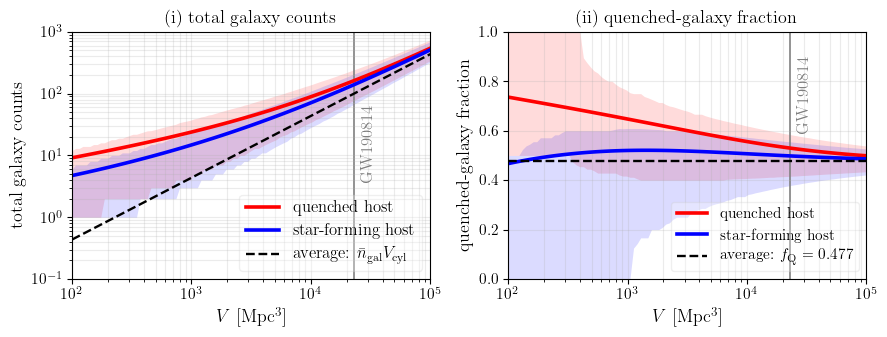

In [18]:
FIG = Path(os.environ.get("HOSTINFER_FIGDIR", "figures"))
if not FIG.is_dir(): FIG = Path("..")/"figures"
FIG.mkdir(parents=True, exist_ok=True)
Q_C, SF_C = "red", "blue"
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.5))

for H, c, mk, lab in (("Q", Q_C, "o", "quenched host"), ("SF", SF_C, "s", "star-forming host")):
    mean_ = np.array([R[k][H]["mu"].sum() for k in range(len(V))])
    lo = np.array([np.percentile(R[k][H]["tot"], 16) for k in range(len(V))])
    hi = np.array([np.percentile(R[k][H]["tot"], 84) for k in range(len(V))])
    a1.plot(V, mean_, color=c, lw=2.6, label=lab)
    a1.fill_between(V, np.maximum(lo, 1e-1), hi, color=c, alpha=.14, lw=0)
        #a1.errorbar(P[:,0], P[:,1], P[:,2], fmt=mk, ms=5.5, color=c, mfc="w", mew=1.5, capsize=2, lw=0, elinewidth=1.1, zorder=5)
a1.plot(V, n_tot_phys*V, color="k", lw=1.7, ls="--", label=r"average: $\bar n_{\rm gal}V_{\rm cyl}$")
a1.axvline(V_GW, color="0.5", lw=1.2, zorder=1)
a1.text(V_GW*1.5, 0.7, "GW190814", rotation=90, ha="right", va="top", fontsize=12, color="0.5", transform=a1.get_xaxis_transform())
a1.set(xscale="log", yscale="log", xlim=(V[0], V[-1]), ylim=(0.1, 1e3))
a1.set_xlabel(r"$V$   [Mpc$^3$]", fontsize=13)
a1.set_ylabel("total galaxy counts", fontsize=13)
a1.set_title("(i) total galaxy counts", fontsize=13)
a1.grid(alpha=.25, which="both"); a1.legend(fontsize=12, loc="lower right", framealpha=0.3)

for H, c, mk, lab in (("Q", Q_C, "o", "quenched host"), ("SF", SF_C, "s", "star-forming host")):
    mu = np.array([R[k][H]["mu"] for k in range(len(V))])
    lo = np.array([np.percentile(R[k][H]["fq"], 16) for k in range(len(V))])
    hi = np.array([np.percentile(R[k][H]["fq"], 84) for k in range(len(V))])
    a2.plot(V, mu[:,0]/mu.sum(1), color=c, lw=2.6, label=lab)
    a2.fill_between(V, lo, hi, color=c, alpha=.14, lw=0)
        #a2.errorbar(P[:,0], P[:,3], P[:,4], fmt=mk, ms=5.5, color=c, mfc="w", mew=1.5, capsize=2, lw=0, elinewidth=1.1, zorder=5)
a2.axhline(f_Q, color="k", lw=1.7, ls="--", label=r"average: $f_{\rm Q}=%.3f$" % f_Q)
a2.axvline(V_GW, color="0.5", lw=1.2, zorder=1)
a2.text(V_GW*1.5, 0.9, "GW190814", rotation=90, ha="right", va="top", fontsize=12, color="0.5", transform=a2.get_xaxis_transform())
a2.set(xscale="log", xlim=(V[0], V[-1]), ylim=(0, 1))
a2.set_xlabel(r"$V$   [Mpc$^3$]", fontsize=13)
a2.set_ylabel("quenched-galaxy fraction", fontsize=13)
a2.set_title("(ii) quenched-galaxy fraction", fontsize=13)
a2.grid(alpha=.25, which="both"); a2.legend(fontsize=11, loc="lower right", framealpha=0.3)
fig.tight_layout()
fig.savefig(FIG/"sfq_environment_PLN.png", dpi=160, bbox_inches="tight")
fig.savefig(FIG/"sfq_environment_PLN.pdf", bbox_inches="tight")
plt.show()